# 03 生命周期分层与高价值风险人群

notebook 02 说明这是个周频平台，一半用户两个月只来一天。这一节要回答：

1. 用户现在分别处在什么状态？哪一层最值得花钱召回？
2. 同一层里谁更值得召回——怎么圈出「高价值风险用户」？
3. 新用户能留下来多少？

快照日取窗口最后一天 2019-11-30。

In [1]:
from nbutils import *
import numpy as np

## 1. 分层口径

低频高客单的平台，「多久没来」比「来得多频繁」更能区分用户状态，所以按 recency 分层。
口径写成 DuckDB 宏 `lifecycle_stage()`（`sql/00_macros.sql`），SQL、看板、notebook 调的都是同一个定义：

| 分层 | 定义 | 含义 |
|---|---|---|
| new 新用户 | 7 天内首次出现 | 还在第一个周期里 |
| healthy 健康 | 7 天内来过 | 符合周频节律 |
| early_risk 早期风险 | 沉默 8–14 天 | 错过了一个周期 |
| accelerating 加速流失 | 沉默 15–30 天 | 错过两到四个周期 |
| long_lapsed 长期沉默 | 沉默 30 天以上 | 基本流失 |

第一档切在 7 天，依据是 notebook 02 的 DAU/WAU ≈ 20%：每周来一两次是常态，一周内没来不算异常。

In [2]:
lc = q("""
    SELECT stage, COUNT(*) AS users,
           AVG(active_days) AS avg_active_days, AVG(total_events) AS avg_events,
           AVG(events_per_active_day) AS events_per_day,
           AVG(CASE WHEN total_orders > 0 THEN 1 ELSE 0 END) AS buyer_rate,
           SUM(total_gmv) AS hist_gmv
    FROM dws_user_lifecycle GROUP BY 1 ORDER BY stage_order(stage)
""")
lc["user_share"] = lc.users / lc.users.sum()
lc["gmv_share"] = lc.hist_gmv / lc.hist_gmv.sum()
lc.assign(stage=lc.stage.map(STAGE_CN))[["stage", "users", "user_share", "gmv_share", "avg_active_days", "avg_events", "events_per_day", "buyer_rate"]] \
  .rename(columns={"stage": "分层", "users": "用户数", "user_share": "用户占比", "gmv_share": "两个月 GMV 占比",
                   "avg_active_days": "人均活跃天数", "avg_events": "人均事件数", "events_per_day": "活跃日人均事件",
                   "buyer_rate": "下过单的比例"}) \
  .style.format({"用户数": "{:,}", "用户占比": "{:.1%}", "两个月 GMV 占比": "{:.1%}", "人均活跃天数": "{:.2f}",
                 "人均事件数": "{:.1f}", "活跃日人均事件": "{:.2f}", "下过单的比例": "{:.1%}"}).hide(axis="index")

分层,用户数,用户占比,两个月 GMV 占比,人均活跃天数,人均事件数,活跃日人均事件,下过单的比例
新用户,"439,316",8.3%,2.3%,1.18,5.8,4.55,5.7%
健康,"964,172",18.1%,43.9%,6.28,54.8,7.02,25.1%
早期风险,"1,035,853",19.5%,23.3%,3.17,24.5,6.26,17.0%
加速流失,"1,311,440",24.7%,15.6%,2.20,13.1,4.87,9.6%
长期沉默,"1,564,310",29.4%,14.9%,1.51,7.6,4.20,8.2%


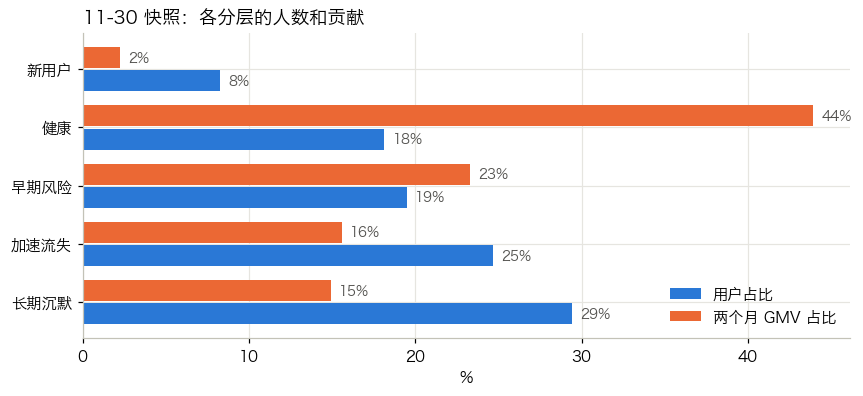

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(lc))
ax.barh(y + 0.2, lc.user_share * 100, height=0.36, color=PALETTE[0], label="用户占比")
ax.barh(y - 0.2, lc.gmv_share * 100, height=0.36, color=PALETTE[1], label="两个月 GMV 占比")
for i, r in lc.iterrows():
    ax.text(r.user_share * 100 + 0.5, i + 0.2, f"{r.user_share:.0%}", va="center", fontsize=9, color="#52514e")
    ax.text(r.gmv_share * 100 + 0.5, i - 0.2, f"{r.gmv_share:.0%}", va="center", fontsize=9, color="#52514e")
ax.set_yticks(y, lc.stage.map(STAGE_CN))
ax.invert_yaxis()
ax.set(xlabel="%", title="11-30 快照：各分层的人数和贡献")
ax.legend(loc="lower right")
plt.show()

- **73% 的用户在 11-30 已经沉默一周以上**（早期风险 + 加速流失 + 长期沉默）。窗口只有两个月，这个比例本身不说明问题，
  但说明「召回」的盘子比「拉新」大得多；
- **早期风险层是最值得看的一层**：人数 19%，却贡献了 23% 的历史 GMV，活跃日人均事件 6.3，接近健康层的 7.0——
  这些人不是不感兴趣，是刚错过了一个周期；
- 长期沉默层人最多（29%），但人均只来过 1.5 天，大面积召回的 ROI 不会高。

## 2. 同一层里谁更值得召回：历史强度

风险层内部差异很大。用「窗口内总事件数」衡量历史强度，看头部用户的集中程度：

In [4]:
conc = q("""
    WITH r AS (
        SELECT stage, total_events, active_days, intensity_pct,
               SUM(total_events) OVER (PARTITION BY stage) AS stage_events,
               RANK() OVER (PARTITION BY stage ORDER BY total_events) AS rk_events,
               RANK() OVER (PARTITION BY stage ORDER BY active_days)  AS rk_days
        FROM dws_user_lifecycle
        WHERE stage IN ('healthy', 'early_risk', 'accelerating')
    )
    SELECT stage,
           SUM(total_events) FILTER (WHERE intensity_pct < 0.1) * 1.0 / MAX(stage_events) AS top10_share,
           SUM(total_events) FILTER (WHERE intensity_pct < 0.3) * 1.0 / MAX(stage_events) AS top30_share,
           SUM(total_events) FILTER (WHERE intensity_pct < 0.5) * 1.0 / MAX(stage_events) AS top50_share,
           AVG(active_days) FILTER (WHERE intensity_pct < 0.3) AS top30_active_days,
           AVG(active_days) AS all_active_days,
           CORR(rk_events, rk_days) AS spearman_events_days
    FROM r GROUP BY 1 ORDER BY stage_order(stage)
""")
conc.assign(stage=conc.stage.map(STAGE_CN)).rename(columns={
    "stage": "分层", "top10_share": "前10%用户的事件占比", "top30_share": "前30%", "top50_share": "前50%",
    "top30_active_days": "前30%人均活跃天数", "all_active_days": "全层人均活跃天数", "spearman_events_days": "事件数与活跃天数的秩相关"}) \
  .style.format({c: "{:.1%}" for c in ["前10%用户的事件占比", "前30%", "前50%"]} |
                {c: "{:.2f}" for c in ["前30%人均活跃天数", "全层人均活跃天数", "事件数与活跃天数的秩相关"]}).hide(axis="index")

分层,前10%用户的事件占比,前30%,前50%,前30%人均活跃天数,全层人均活跃天数,事件数与活跃天数的秩相关
健康,48.0%,77.7%,90.8%,11.83,6.28,0.84
早期风险,52.1%,82.7%,93.6%,6.16,3.17,0.80
加速流失,53.4%,83.0%,92.3%,3.92,2.20,0.72


- 两个风险层里，**前 30% 的用户贡献了约 83% 的事件**，是很标准的帕累托分布；而且从早期风险到加速流失，集中度几乎没变——
  头部用户并没有因为沉默更久就先走掉；
- 分布是连续的、没有天然断点，所以不用拍一个绝对阈值（比如「事件数 ≥ 10」），而是**在每一层内按排名取前 30%**，
  这样两层的筛选强度一致，人数也随层的规模自动伸缩；
- **稳健性**：事件数和活跃天数的秩相关在 0.72–0.84 之间，前 30% 的人均活跃天数是全层的 1.8–1.9 倍。
  按事件数筛出来的不是「某一天刷了很多」的人，而是确实来得更勤的人。

In [5]:
fun = q("""
    WITH u AS (
        SELECT user_id, stage, intensity_pct < 0.3 AS top30
        FROM dws_user_lifecycle WHERE stage IN ('healthy', 'early_risk', 'accelerating')
    ),
    a AS (SELECT user_id, SUM(carts) AS carts, SUM(orders) AS orders, SUM(gmv) AS gmv FROM dws_user_daily GROUP BY 1)
    SELECT stage, top30, COUNT(*) AS users,
           AVG(CASE WHEN carts > 0 THEN 1 ELSE 0 END)  AS carted,
           AVG(CASE WHEN orders > 0 THEN 1 ELSE 0 END) AS bought,
           SUM(gmv) AS gmv
    FROM u JOIN a USING (user_id) GROUP BY 1, 2 ORDER BY stage_order(stage), top30 DESC
""")
fun["gmv_share_in_stage"] = fun.gmv / fun.groupby("stage").gmv.transform("sum")
fun.assign(stage=fun.stage.map(STAGE_CN), top30=fun.top30.map({True: "前30%", False: "后70%"})) \
   .rename(columns={"stage": "分层", "top30": "强度", "users": "用户数", "carted": "加购过的比例", "bought": "下过单的比例",
                    "gmv_share_in_stage": "层内 GMV 占比"}) \
   [["分层", "强度", "用户数", "加购过的比例", "下过单的比例", "层内 GMV 占比"]] \
   .style.format({"用户数": "{:,}", "加购过的比例": "{:.1%}", "下过单的比例": "{:.1%}", "层内 GMV 占比": "{:.1%}"}).hide(axis="index")

分层,强度,用户数,加购过的比例,下过单的比例,层内 GMV 占比
健康,前30%,"291,188",70.0%,48.3%,74.4%
健康,后70%,"672,984",26.4%,15.0%,25.6%
早期风险,前30%,"320,625",59.1%,36.9%,78.2%
早期风险,后70%,"715,228",15.8%,8.2%,21.8%
加速流失,前30%,"422,723",32.2%,22.4%,86.4%
加速流失,后70%,"888,717",6.0%,3.5%,13.6%


**高价值风险用户 = 早期风险层和加速流失层中，各自历史强度前 30% 的用户**，11-30 这天共约 74 万人。
早期风险层的前 30% 里，37% 的人在窗口内下过单（后 70% 只有 8%），贡献了这一层 78% 的 GMV。

这个圈人规则是「看起来有价值」。下一节（notebook 04）检验它能不能**预测**谁会自己回来、谁需要被召回。

## 3. 流失是不是因为「不喜欢这里的东西」？

如果高价值风险用户和健康用户逛的品类、看的价位都一样，说明他们不是因为货不对才走的，而是节律断了——
召回内容可以直接沿用他们原来的兴趣品类，不需要换货。

In [6]:
cat = q("""
    WITH u AS (
        SELECT user_id, CASE WHEN stage = 'healthy' THEN 'healthy' ELSE 'risk_top30' END AS grp
        FROM dws_user_lifecycle
        WHERE stage = 'healthy' OR (stage IN ('early_risk', 'accelerating') AND intensity_pct < 0.3)
    ),
    c AS (
        SELECT u.grp, e.category_code, COUNT(DISTINCT e.user_id) AS users, median(e.price) AS median_price
        FROM dwd_events e JOIN u USING (user_id)
        WHERE e.event_type = 'view' AND e.category_code <> 'unknown'
        GROUP BY 1, 2
    )
    SELECT *, RANK() OVER (PARTITION BY grp ORDER BY users DESC) AS rk FROM c
""")
top = cat[cat.grp == "healthy"].nsmallest(10, "rk")[["category_code", "rk", "median_price"]] \
    .merge(cat[cat.grp == "risk_top30"][["category_code", "rk", "median_price"]], on="category_code", suffixes=("_健康", "_高价值风险"))
top.columns = ["品类", "健康层排名", "健康层浏览价中位数", "高价值风险层排名", "高价值风险层浏览价中位数"]
top.style.format({"健康层浏览价中位数": "{:,.0f}", "高价值风险层浏览价中位数": "{:,.0f}"}).hide(axis="index")

品类,健康层排名,健康层浏览价中位数,高价值风险层排名,高价值风险层浏览价中位数
electronics.smartphone,1,298,1,283
electronics.audio.headphone,2,102,3,102
electronics.clocks,3,180,2,179
electronics.video.tv,4,401,4,382
apparel.shoes,5,85,5,86
computers.notebook,6,643,7,543
appliances.environment.vacuum,7,124,6,118
appliances.kitchen.refrigerators,8,306,8,296
appliances.kitchen.washer,9,322,9,319
apparel.shoes.keds,10,69,10,72


两组人浏览最多的前 10 个品类几乎一样（手机遥遥领先），排名最多差一两位，各品类的浏览价位中位数也接近。
**流失不是品类或价格错配造成的，更像是一次需求满足后没有新的触发点。** 召回时用「原兴趣品类的降价 / 新品」做内容，比泛泛的优惠券更对路。

## 4. 分层结构在 11 月的变化

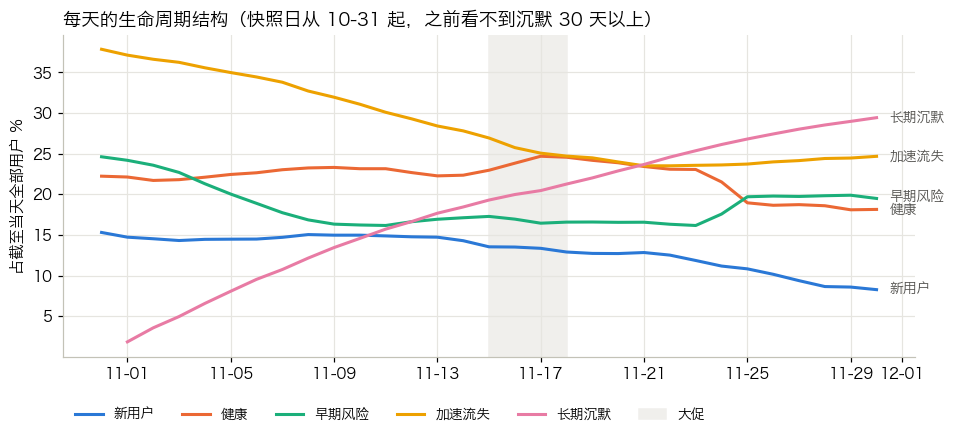

In [7]:
ld = q("SELECT * FROM ads_lifecycle_daily ORDER BY snapshot_date")
ld["snapshot_date"] = pd.to_datetime(ld.snapshot_date)
fig, ax = plt.subplots(figsize=(10, 3.8))
ends = {}
for s in STAGES:
    x = ld[ld.stage == s]
    ax.plot(x.snapshot_date, x.user_share * 100, color=STAGE_COLOR[s], label=STAGE_CN[s])
    ends[s] = x.user_share.iloc[-1] * 100
prev = None
for s, v in sorted(ends.items(), key=lambda kv: kv[1]):   # 末端标签错开，避免重叠
    v = v if prev is None else max(v, prev + 1.6)
    ax.text(ld.snapshot_date.max() + pd.Timedelta(hours=12), v, STAGE_CN[s], va="center", fontsize=9, color="#52514e")
    prev = v
ax.xaxis.set_major_formatter(__import__("matplotlib.dates", fromlist=["DateFormatter"]).DateFormatter("%m-%d"))
ax.axvspan(pd.Timestamp("2019-11-15"), pd.Timestamp("2019-11-17 23:59"), color=SHADE, zorder=0, label="大促")
ax.set(ylabel="占截至当天全部用户 %", title="每天的生命周期结构（快照日从 10-31 起，之前看不到沉默 30 天以上）")
ax.legend(ncol=6, loc="upper left", fontsize=9, bbox_to_anchor=(0, -0.12))
plt.show()

两个现象：

- **长期沉默层一路上涨**，主要是窗口越拉越长造成的——10-31 时最多只能看到沉默 30 天，到 11-30 能看到 60 天。
  两个月的数据里，这条线不能读成「流失在加速」；
- **大促拉回的人，一周后又成批滑走了。** 大促期间健康层占比抬升了约 2 个百分点；整整一周之后（11-24、11-25），
  健康层一下掉了 4 个百分点、早期风险层跳涨 3.5 个百分点——大促那几天回来的人，下一周没有再来。
  大促能把人拉回来，但留不住；**大促后第二周正是「早期风险」的召回窗口**，这和 notebook 04 找到的干预时机是同一件事。

## 5. 新用户留存

「新用户」= 在窗口内第一次出现的用户。两种口径：

- **第 N 天留存**：第 N 天当天回来了——日频产品的常用口径；
- **N 天内回访率**：第 1 到 N 天里至少回来过一次——更适合周频平台。

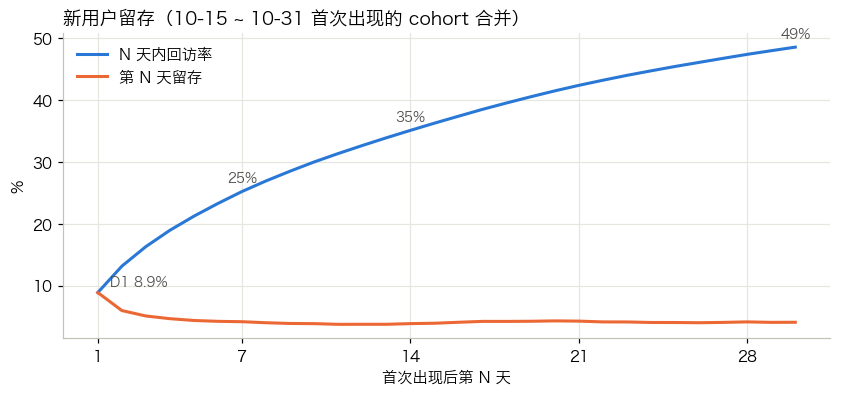

In [8]:
r = q("""
    SELECT day_n, SUM(retained_users) * 1.0 / SUM(cohort_size) AS on_day,
           SUM(returned_within_users) * 1.0 / SUM(cohort_size) AS within_n
    FROM ads_retention_cohort
    WHERE cohort_date BETWEEN '2019-10-15' AND '2019-10-31'   -- 避开左截断，且观察期满 30 天
    GROUP BY 1 ORDER BY 1
""")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(r.day_n, r.within_n * 100, color=PALETTE[0], label="N 天内回访率")
ax.plot(r.day_n, r.on_day * 100, color=PALETTE[1], label="第 N 天留存")
for n in (7, 14, 30):
    v = r.set_index("day_n").loc[n]
    ax.annotate(f"{v.within_n:.0%}", (n, v.within_n * 100), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=9, color="#52514e")
ax.annotate(f"D1 {r.on_day.iloc[0]:.1%}", (1, r.on_day.iloc[0] * 100), xytext=(8, 4), textcoords="offset points", fontsize=9, color="#52514e")
ax.set(xlabel="首次出现后第 N 天", ylabel="%", title="新用户留存（10-15 ~ 10-31 首次出现的 cohort 合并）", xticks=[1, 7, 14, 21, 28])
ax.legend()
plt.show()

第 7 天当天回来的只有 4%，但 7 天内回来过的有 25%，30 天内接近一半。用日频口径报留存，会严重低估这个平台的用户粘性。

In [9]:
wk = q("""
    SELECT cohort_week, SUM(cohort_size) / COUNT(DISTINCT day_n) AS cohort_users, day_n,
           SUM(returned_within_users) * 1.0 / SUM(cohort_size) AS within_n
    FROM ads_retention_cohort WHERE day_n IN (1, 7, 14)
    GROUP BY 1, 3
""").pivot_table(index="cohort_week", columns="day_n", values="within_n")
wk.index = pd.to_datetime(wk.index).strftime("%m-%d 当周")
wk.columns = [f"{c} 天内回访率" for c in wk.columns]
wk.style.format("{:.1%}", na_rep="观察期不足")

,1 天内回访率,7 天内回访率,14 天内回访率
cohort_week,,,
09-30 当周,13.7%,39.8%,52.3%
10-07 当周,10.6%,31.9%,43.1%
10-14 当周,9.5%,27.6%,37.4%
10-21 当周,8.4%,23.3%,33.6%
10-28 当周,8.9%,26.1%,36.1%
11-04 当周,9.4%,27.2%,37.5%
11-11 当周,15.2%,31.8%,39.7%
11-18 当周,9.5%,23.7%,观察期不足
11-25 当周,8.8%,观察期不足,观察期不足


按周看 cohort，10 月第一周的 7 天内回访率高达 40%，之后逐周下降，到 10 月下旬稳定在 23%–27%。
这不是新用户质量在变差，而是**左截断**：窗口从 10-01 开始，10 月初「第一次出现」的人里混了大量 9 月就来过的老用户。
所以新用户指标要从 10 月中旬以后的 cohort 读。

11-11 当周的 cohort 明显偏高（7 天内回访 32%），因为大促正好落在他们的头 7 天里——大促把一批新用户「拉回来了第二次」。